In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [6]:
ddi = pd.read_csv("DrugBank_known_ddi.txt", sep="\t", header=None)
drug_info = pd.read_csv("Drug_info_combined.csv")
interaction_info = pd.read_csv("Interaction_information.txt", sep="\t")
enzyme_info = pd.read_csv("Approved_drug_enzyme_Information.txt", sep="\t", header=None)

In [7]:
ddi.columns = ["Drug1", "Drug2", "Interaction_ID"]

enzyme_info.columns = [
    "DrugBank_ID",
    "Drug",
    "Enzyme",
    "Species",
    "Uniprot_ID",
    "Role"
]

In [8]:
print("DDI shape:", ddi.shape)
print("Drug info shape:", drug_info.shape)
print("Interaction info shape:", interaction_info.shape)
print("Enzyme info shape:", enzyme_info.shape)

display(ddi.head())
display(drug_info.head())
display(interaction_info.head())
display(enzyme_info.head())

DDI shape: (222128, 3)
Drug info shape: (2386, 4)
Interaction info shape: (113, 4)
Enzyme info shape: (6440, 6)


,Drug1,Drug2,Interaction_ID
0,drug1,drug2,Label
1,DB01115,DB08807,1
2,DB01115,DB00187,1
3,DB01115,DB00871,1
4,DB01115,DB01295,1


,Unnamed: 0,Drug name,Name,Smiles
0,0,DB00006,Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...
1,1,DB00014,Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...
2,2,DB00035,Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...
3,3,DB00050,Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...
4,4,DB00080,Daptomycin,CCCCCCCCCC(=O)N[C@@H](CC1=CNC2=C1C=CC=C2)C(=O)...


,Interaction type,Description,Subject,DDI type
0,3,1,The risk or severity of congestive heart failu...,Type_56
1,2,2,#Drug1 may decrease the excretion rate of #Dru...,Type_53
2,2,3,The serum concentration of #Drug2 can be incre...,Type_52
3,3,4,The risk or severity of anemia and severe leuk...,Type_50
4,3,38,The risk or severity of sedation and somnolenc...,Type_108


,DrugBank_ID,Drug,Enzyme,Species,Uniprot_ID,Role
0,DB00005,Etanercept,Prostaglandin G/H synthase 2,Human,P35354,inhibitor
1,DB00006,Bivalirudin,Myeloperoxidase,Human,P05164,inhibitor
2,DB00008,Peginterferon alfa-2a,Cytochrome P450 1A2,Human,P05177,inhibitor
3,DB00022,Peginterferon alfa-2b,Cytochrome P450 1A2,Human,P05177,inhibitor
4,DB00022,Peginterferon alfa-2b,Cytochrome P450 2D6,Human,P10635,inhibitor


In [9]:
conda install -c conda-forge rdkit

Jupyter detected...
3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: C:\Users\user\anaconda3\envs\mers_retrain

  added / updated specs:
    - rdkit


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.6.17  |       h4c7d964_0         126 KB  conda-forge
    ------------------------------------------------------------
                                           Total:         126 KB

The following packages will be UPDATED:

  ca-certificates                      2026.5.20-h4c7d964_0 --> 2026.6.17-h4c7d964_0 



ca-certificates-2026 | 126 KB    |            |   0% 
ca-certificates-2026 | 126 KB    | #2         |  13% 
ca-certificates-2026 | 126 KB    | ########## | 100% 
ca-certificates-2026 | 126 KB    | ########## | 100% 
             



==> WARNING: A newer version of conda exists. <==
    current version: 25.11.1
    latest version: 26.5.3

Please update conda by running

    $ conda update -n base -c defaults conda




In [10]:
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

In [11]:
def smiles_to_morgan(smiles, radius=2, n_bits=2048):
    
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )

    return np.array(fp)

In [12]:
drug_map = dict(
    zip(
        drug_info["Drug name"],
        drug_info["Smiles"]
    )
)

ddi["SMILES1"] = ddi["Drug1"].map(drug_map)
ddi["SMILES2"] = ddi["Drug2"].map(drug_map)

In [13]:
ddi.head()

,Drug1,Drug2,Interaction_ID,SMILES1,SMILES2
0,drug1,drug2,Label,NaN,NaN
1,DB01115,DB08807,1,COC(=O)C1=C(C)NC(C)=C(C1C1=CC=CC=C1[N+]([O-])=...,CC1=CC2=C(N1)C=CC=C2OCC(CNC(C)(C)C)OC(=O)C1=CC...
2,DB01115,DB00187,1,COC(=O)C1=C(C)NC(C)=C(C1C1=CC=CC=C1[N+]([O-])=...,COC(=O)CCC1=CC=C(OCC(O)CNC(C)C)C=C1
3,DB01115,DB00871,1,COC(=O)C1=C(C)NC(C)=C(C1C1=CC=CC=C1[N+]([O-])=...,CC(C)(C)NCC(O)C1=CC(O)=CC(O)=C1
4,DB01115,DB01295,1,COC(=O)C1=C(C)NC(C)=C(C1C1=CC=CC=C1[N+]([O-])=...,COC1=C(OC)C=C(CCNCC(O)COC2=CC=CC(C)=C2)C=C1


In [14]:
print(ddi["SMILES1"].notna().sum())
print(ddi["SMILES2"].notna().sum())

print(
    ddi[["SMILES1","SMILES2"]]
    .dropna()
    .shape
)

222127
222127
(222127, 2)


In [15]:
ddi = ddi.dropna(subset=["SMILES1","SMILES2"])

In [16]:
fp = smiles_to_morgan(
    ddi["SMILES1"].iloc[0]
)

print(fp.shape)
print(fp.sum())

(2048,)
37


[23:00:01] DEPRECATION WARNING: please use MorganGenerator


In [17]:
print(ddi["Interaction_ID"].nunique())
print(ddi["Interaction_ID"].value_counts().head(20))

113
Interaction_ID
113    62996
89     37204
3      27258
20     11765
75      9937
74      9729
53      5884
104     5342
34      5300
80      3813
60      3520
10      2819
81      2399
58      2379
47      2106
108     1825
13      1614
57      1503
95      1499
109     1452
Name: count, dtype: int64


In [18]:
interaction_info.head()

,Interaction type,Description,Subject,DDI type
0,3,1,The risk or severity of congestive heart failu...,Type_56
1,2,2,#Drug1 may decrease the excretion rate of #Dru...,Type_53
2,2,3,The serum concentration of #Drug2 can be incre...,Type_52
3,3,4,The risk or severity of anemia and severe leuk...,Type_50
4,3,38,The risk or severity of sedation and somnolenc...,Type_108


In [19]:
interaction_info[["Description","Interaction type"]].head(20)

,Description,Interaction type
0,1,3
1,2,2
2,3,2
3,4,3
4,38,3
5,6,2
6,7,3
7,8,3
8,9,3
9,10,2


In [20]:
interaction_info["Interaction type"].value_counts()

Interaction type
2    81
3    32
Name: count, dtype: int64

In [21]:
print(ddi["Interaction_ID"].dtype)
print(interaction_info["Description"].dtype)

object
int64


In [22]:
ddi["Interaction_ID"] = ddi["Interaction_ID"].astype(int)
interaction_info["Description"] = interaction_info["Description"].astype(int)

interaction_map = dict(
    zip(
        interaction_info["Description"],
        interaction_info["Interaction type"]
    )
)

ddi["Level1"] = ddi["Interaction_ID"].map(interaction_map)

print(ddi["Level1"].value_counts())

Level1
2    155183
3     66944
Name: count, dtype: int64


C:\Users\user\AppData\Local\Temp\ipykernel_27636\872353695.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ddi["Interaction_ID"] = ddi["Interaction_ID"].astype(int)
C:\Users\user\AppData\Local\Temp\ipykernel_27636\872353695.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ddi["Level1"] = ddi["Interaction_ID"].map(interaction_map)


In [23]:
ddi = ddi.copy()

ddi["Level1_binary"] = ddi["Level1"].replace({
    2: 0,   # PK
    3: 1    # PD
})

print(ddi["Level1_binary"].value_counts())

Level1_binary
0    155183
1     66944
Name: count, dtype: int64


In [24]:
print(
    ddi["Level1_binary"]
    .value_counts(normalize=True) * 100
)

Level1_binary
0    69.862286
1    30.137714
Name: proportion, dtype: float64


In [25]:
y = ddi["Level1_binary"]

In [26]:
# حفظ نسخة نظيفة من بيانات DDI بعد إضافة SMILES و Level1
ddi_clean = ddi.copy()

ddi_clean.to_csv(
    "DDI_clean_with_SMILES_Level1.csv",
    index=False
)

print("Saved: DDI_clean_with_SMILES_Level1.csv")
print(ddi_clean.shape)

Saved: DDI_clean_with_SMILES_Level1.csv
(222127, 7)


In [27]:
# حفظ جدول معلومات التفاعلات
interaction_info.to_csv(
    "Interaction_information_clean.csv",
    index=False
)

print("Saved: Interaction_information_clean.csv")

Saved: Interaction_information_clean.csv


In [28]:
# حفظ بيانات الإنزيمات المنظمة
enzyme_info.to_csv(
    "Enzyme_information_clean.csv",
    index=False
)

print("Saved: Enzyme_information_clean.csv")

Saved: Enzyme_information_clean.csv


In [29]:
from sklearn.model_selection import train_test_split

ddi_sample, _ = train_test_split(
    ddi,
    train_size=20000,
    stratify=ddi["Level1_binary"],
    random_state=42
)

print(ddi_sample["Level1_binary"].value_counts())

Level1_binary
0    13972
1     6028
Name: count, dtype: int64


In [30]:
ddi_sample, _ = train_test_split(
    ddi,
    train_size=20000,
    stratify=ddi["Level1_binary"],
    random_state=42
)

print(ddi_sample["Level1_binary"].value_counts())

Level1_binary
0    13972
1     6028
Name: count, dtype: int64


In [31]:
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

In [32]:
drug_fps = {}

for drug_id, smiles in zip(
    drug_info["Drug name"],
    drug_info["Smiles"]
):
    
    fp = smiles_to_morgan(smiles)

    if fp is not None:
        drug_fps[drug_id] = fp

print("Number of fingerprints:", len(drug_fps))

Number of fingerprints: 2385


In [33]:
import pickle

with open("drug_fingerprints.pkl", "wb") as f:
    pickle.dump(drug_fps, f)

print("drug_fingerprints.pkl saved")

drug_fingerprints.pkl saved


In [34]:
X = []
y = []

for _, row in ddi_sample.iterrows():

    drug1 = row["Drug1"]
    drug2 = row["Drug2"]

    if drug1 not in drug_fps:
        continue

    if drug2 not in drug_fps:
        continue

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    pair_fp = np.concatenate([fp1, fp2])

    X.append(pair_fp)
    y.append(row["Level1_binary"])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20000, 4096)
y shape: (20000,)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(16000, 4096)
(4000, 4096)


In [36]:
from xgboost import XGBClassifier

In [37]:
xgb_level1 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_level1.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [38]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = xgb_level1.predict(X_test)
y_proba = xgb_level1.predict_proba(X_test)[:,1]

print("Accuracy =", accuracy_score(y_test, y_pred))
print("ROC-AUC  =", roc_auc_score(y_test, y_proba))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

Accuracy = 0.85575
ROC-AUC  = 0.9215215974529644

Classification Report
              precision    recall  f1-score   support

           0       0.86      0.95      0.90      2794
           1       0.85      0.63      0.72      1206

    accuracy                           0.86      4000
   macro avg       0.86      0.79      0.81      4000
weighted avg       0.86      0.86      0.85      4000


Confusion Matrix
[[2664  130]
 [ 447  759]]


In [39]:
import pickle

with open("Level1_XGBoost_Model.pkl", "wb") as f:
    pickle.dump(xgb_level1, f)

print("Model saved")

Model saved


In [40]:
import numpy as np

np.save("X_test_Level1.npy", X_test)
np.save("y_test_Level1.npy", y_test)

print("Test set saved")

Test set saved


In [41]:
np.save("y_pred_Level1.npy", y_pred)
np.save("y_proba_Level1.npy", y_proba)

print("Predictions saved")

Predictions saved


In [42]:
import pandas as pd

results = pd.DataFrame({
    "True_Label": y_test,
    "Predicted_Label": y_pred,
    "Probability_PD": y_proba
})

results.to_csv(
    "Level1_Test_Predictions.csv",
    index=False
)

print("Results CSV saved")

Results CSV saved


In [43]:
metrics = pd.DataFrame({
    "Metric":["Accuracy","ROC_AUC"],
    "Value":[0.85575,0.92152]
})

metrics.to_csv(
    "Level1_Metrics.csv",
    index=False
)

metrics

,Metric,Value
0,Accuracy,0.85575
1,ROC_AUC,0.92152


In [44]:
print(enzyme_info.columns.tolist())
enzyme_info.head()

['DrugBank_ID', 'Drug', 'Enzyme', 'Species', 'Uniprot_ID', 'Role']


,DrugBank_ID,Drug,Enzyme,Species,Uniprot_ID,Role
0,DB00005,Etanercept,Prostaglandin G/H synthase 2,Human,P35354,inhibitor
1,DB00006,Bivalirudin,Myeloperoxidase,Human,P05164,inhibitor
2,DB00008,Peginterferon alfa-2a,Cytochrome P450 1A2,Human,P05177,inhibitor
3,DB00022,Peginterferon alfa-2b,Cytochrome P450 1A2,Human,P05177,inhibitor
4,DB00022,Peginterferon alfa-2b,Cytochrome P450 2D6,Human,P10635,inhibitor


In [45]:
enzyme_info = enzyme_info.copy()

enzyme_info["DrugBank_ID"] = enzyme_info["DrugBank_ID"].astype(str)
enzyme_info["Enzyme"] = enzyme_info["Enzyme"].astype(str)
enzyme_info["Role"] = enzyme_info["Role"].astype(str).str.lower()

enzyme_info = enzyme_info[
    (enzyme_info["Enzyme"] != "None") &
    (enzyme_info["Role"] != "none")
].copy()

print(enzyme_info.shape)
enzyme_info.head()

(6440, 6)


,DrugBank_ID,Drug,Enzyme,Species,Uniprot_ID,Role
0,DB00005,Etanercept,Prostaglandin G/H synthase 2,Human,P35354,inhibitor
1,DB00006,Bivalirudin,Myeloperoxidase,Human,P05164,inhibitor
2,DB00008,Peginterferon alfa-2a,Cytochrome P450 1A2,Human,P05177,inhibitor
3,DB00022,Peginterferon alfa-2b,Cytochrome P450 1A2,Human,P05177,inhibitor
4,DB00022,Peginterferon alfa-2b,Cytochrome P450 2D6,Human,P10635,inhibitor


In [46]:
drug_enzymes = enzyme_info.groupby("DrugBank_ID")["Enzyme"].apply(set).to_dict()

drug_cyps = enzyme_info[
    enzyme_info["Enzyme"].str.contains("Cytochrome P450|CYP", case=False, na=False)
].groupby("DrugBank_ID")["Enzyme"].apply(set).to_dict()

drug_roles = enzyme_info.groupby("DrugBank_ID").apply(
    lambda df: set(zip(df["Enzyme"], df["Role"]))
).to_dict()

print("Drugs with enzymes:", len(drug_enzymes))
print("Drugs with CYPs:", len(drug_cyps))
print("Drugs with enzyme roles:", len(drug_roles))

Drugs with enzymes: 1269
Drugs with CYPs: 992
Drugs with enzyme roles: 1269


C:\Users\user\AppData\Local\Temp\ipykernel_27636\1898388121.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  drug_roles = enzyme_info.groupby("DrugBank_ID").apply(


In [47]:
def enzyme_pair_features(drug1, drug2):

    enzymes1 = drug_enzymes.get(drug1, set())
    enzymes2 = drug_enzymes.get(drug2, set())

    cyps1 = drug_cyps.get(drug1, set())
    cyps2 = drug_cyps.get(drug2, set())

    roles1 = drug_roles.get(drug1, set())
    roles2 = drug_roles.get(drug2, set())

    shared_enzymes = len(enzymes1.intersection(enzymes2))
    shared_cyps = len(cyps1.intersection(cyps2))

    inhibitor_substrate_conflict = 0
    inducer_substrate_conflict = 0

    for enzyme in enzymes1.intersection(enzymes2):

        roles_drug1 = {role for enz, role in roles1 if enz == enzyme}
        roles_drug2 = {role for enz, role in roles2 if enz == enzyme}

        if (
            ("inhibitor" in roles_drug1 and "substrate" in roles_drug2)
            or
            ("substrate" in roles_drug1 and "inhibitor" in roles_drug2)
        ):
            inhibitor_substrate_conflict = 1

        if (
            ("inducer" in roles_drug1 and "substrate" in roles_drug2)
            or
            ("substrate" in roles_drug1 and "inducer" in roles_drug2)
        ):
            inducer_substrate_conflict = 1

    return np.array([
        shared_enzymes,
        shared_cyps,
        inhibitor_substrate_conflict,
        inducer_substrate_conflict
    ])

In [48]:
enzyme_pair_features(
    ddi_sample.iloc[0]["Drug1"],
    ddi_sample.iloc[0]["Drug2"]
)

array([0, 0, 0, 0])

In [49]:
X_enhanced = []
y_enhanced = []

for _, row in ddi_sample.iterrows():

    drug1 = row["Drug1"]
    drug2 = row["Drug2"]

    if drug1 not in drug_fps:
        continue

    if drug2 not in drug_fps:
        continue

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    morgan_features = np.concatenate([fp1, fp2])

    enzyme_features = enzyme_pair_features(
        drug1,
        drug2
    )

    pair_features = np.concatenate([
        morgan_features,
        enzyme_features
    ])

    X_enhanced.append(pair_features)
    y_enhanced.append(row["Level1_binary"])

X_enhanced = np.array(X_enhanced)
y_enhanced = np.array(y_enhanced)

print("X_enhanced:", X_enhanced.shape)
print("y_enhanced:", y_enhanced.shape)

X_enhanced: (20000, 4100)
y_enhanced: (20000,)


In [50]:
from sklearn.model_selection import train_test_split

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.2,
    random_state=42,
    stratify=y_enhanced
)

print(Xe_train.shape)
print(Xe_test.shape)

(16000, 4100)
(4000, 4100)


In [51]:
xgb_level1_enzyme = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_level1_enzyme.fit(Xe_train, ye_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [52]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

ye_pred = xgb_level1_enzyme.predict(Xe_test)
ye_proba = xgb_level1_enzyme.predict_proba(Xe_test)[:,1]

print("Accuracy =", accuracy_score(ye_test, ye_pred))
print("ROC-AUC =", roc_auc_score(ye_test, ye_proba))

print("\nClassification Report")
print(classification_report(ye_test, ye_pred))

print("\nConfusion Matrix")
print(confusion_matrix(ye_test, ye_pred))

Accuracy = 0.862
ROC-AUC = 0.9232212238734745

Classification Report
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      2794
           1       0.85      0.66      0.74      1206

    accuracy                           0.86      4000
   macro avg       0.86      0.81      0.82      4000
weighted avg       0.86      0.86      0.86      4000


Confusion Matrix
[[2648  146]
 [ 406  800]]


In [53]:
import pickle

with open("Level1_XGBoost_Enzyme_Model.pkl", "wb") as f:
    pickle.dump(xgb_level1_enzyme, f)

print("Enhanced model saved")

Enhanced model saved


In [54]:
enzyme_feature_names = [
    "shared_enzymes",
    "shared_cyps",
    "inhibitor_substrate_conflict",
    "inducer_substrate_conflict"
]

In [55]:
import pandas as pd

importances = xgb_level1_enzyme.feature_importances_

enzyme_importance = pd.DataFrame({
    "Feature": enzyme_feature_names,
    "Importance": importances[-4:]
}).sort_values("Importance", ascending=False)

enzyme_importance

,Feature,Importance
1,shared_cyps,0.010201
0,shared_enzymes,0.002280
2,inhibitor_substrate_conflict,0.001460
3,inducer_substrate_conflict,0.000764


In [56]:
enzyme_importance.to_csv(
    "Level1_Enzyme_Feature_Importance.csv",
    index=False
)

print("Saved: Level1_Enzyme_Feature_Importance.csv")

Saved: Level1_Enzyme_Feature_Importance.csv


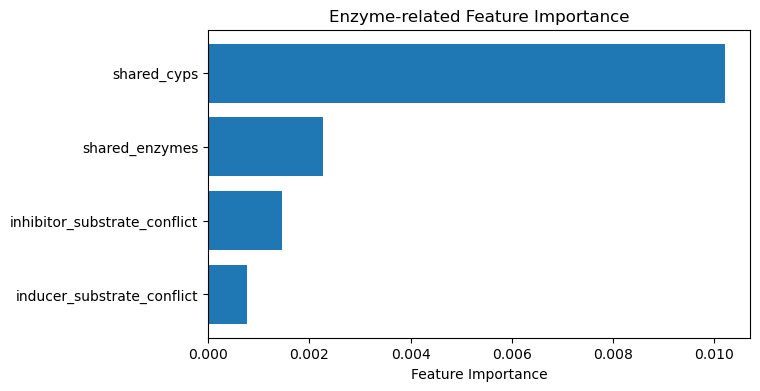

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.barh(
    enzyme_importance["Feature"],
    enzyme_importance["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("Enzyme-related Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [58]:
import joblib

joblib.dump(
    xgb_level1_enzyme,
    "XGB_Level1_Morgan_Enzyme.pkl"
)

print("Model saved")

Model saved


In [59]:
np.save("Xe_test.npy", Xe_test)
np.save("ye_test.npy", ye_test)
np.save("ye_pred.npy", ye_pred)
np.save("ye_proba.npy", ye_proba)

print("Test data and predictions saved")

Test data and predictions saved


In [60]:
metrics_modelB = pd.DataFrame({
    "Model": ["Morgan + Enzyme"],
    "Accuracy": [accuracy_score(ye_test, ye_pred)],
    "ROC_AUC": [roc_auc_score(ye_test, ye_proba)]
})

metrics_modelB.to_csv(
    "Level1_ModelB_Metrics.csv",
    index=False
)

metrics_modelB

,Model,Accuracy,ROC_AUC
0,Morgan + Enzyme,0.862,0.923221


In [61]:
side_effects = pd.read_csv(
    "Drug_Side_Effect.txt",
    sep="\t",
    header=None
)

print(side_effects.shape)
display(side_effects.head(10))

(18076, 6)


,0,1,2,3,4,5
0,DrugBank ID,SIDE EFFECT,MIN,MEAN,MAX,Drug name
1,DB00006,Abdominal pain,1.0,3.53333333333,4.83,Bivalirudin
2,DB00006,Angina pectoris,5.2,5.25,5.3,Bivalirudin
3,DB00006,Anxiety,5.88,6.195,6.51,Bivalirudin
4,DB00006,Atrial fibrillation,1.0,1.05,1.1,Bivalirudin
5,DB00006,Back pain,2.8,21.714285714299997,43.9,Bivalirudin
6,DB00006,Body temperature increased,1.0,2.9725,5.02,Bivalirudin
7,DB00006,Bradycardia,1.2,4.76,7.62,Bivalirudin
8,DB00006,Chest pain,2.3,3.13333333333,3.7,Bivalirudin
9,DB00006,Dyspepsia,4.63,4.895,5.16,Bivalirudin


In [62]:
side_effects.columns = [
    "DrugBank_ID",
    "Side_Effect",
    "MIN",
    "MEAN",
    "MAX",
    "Drug_Name"
]

side_effects = side_effects.iloc[1:].reset_index(drop=True)

print(side_effects.shape)
display(side_effects.head())

(18075, 6)


,DrugBank_ID,Side_Effect,MIN,MEAN,MAX,Drug_Name
0,DB00006,Abdominal pain,1.0,3.53333333333,4.83,Bivalirudin
1,DB00006,Angina pectoris,5.2,5.25,5.3,Bivalirudin
2,DB00006,Anxiety,5.88,6.195,6.51,Bivalirudin
3,DB00006,Atrial fibrillation,1.0,1.05,1.1,Bivalirudin
4,DB00006,Back pain,2.8,21.714285714299997,43.9,Bivalirudin


In [63]:
print(
    side_effects["DrugBank_ID"].nunique()
)

567


In [64]:
drug_sideeffects = (
    side_effects
    .groupby("DrugBank_ID")["Side_Effect"]
    .apply(set)
    .to_dict()
)

print(
    "Drugs with side effects:",
    len(drug_sideeffects)
)

Drugs with side effects: 567


In [65]:
count_both = 0
count_one = 0
count_none = 0

for _, row in ddi_sample.iterrows():

    d1 = row["Drug1"]
    d2 = row["Drug2"]

    has1 = d1 in drug_sideeffects
    has2 = d2 in drug_sideeffects

    if has1 and has2:
        count_both += 1

    elif has1 or has2:
        count_one += 1

    else:
        count_none += 1

print("Both drugs:", count_both)
print("One drug :", count_one)
print("None     :", count_none)

Both drugs: 2905
One drug : 9291
None     : 7804


In [66]:
print(side_effects["Side_Effect"].nunique())

1579


In [67]:
def sideeffect_pair_features(drug1, drug2):

    se1 = drug_sideeffects.get(drug1, set())
    se2 = drug_sideeffects.get(drug2, set())

    shared = len(se1.intersection(se2))
    union = len(se1.union(se2))

    if union > 0:
        jaccard = shared / union
    else:
        jaccard = 0

    return np.array([
        shared,
        union,
        jaccard
    ])

In [68]:
sideeffect_pair_features(
    ddi_sample.iloc[0]["Drug1"],
    ddi_sample.iloc[0]["Drug2"]
)

array([0, 0, 0])

In [69]:
X_full = []
y_full = []

for _, row in ddi_sample.iterrows():

    drug1 = row["Drug1"]
    drug2 = row["Drug2"]

    if drug1 not in drug_fps:
        continue

    if drug2 not in drug_fps:
        continue

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    morgan_features = np.concatenate([fp1, fp2])

    enzyme_features = enzyme_pair_features(
        drug1,
        drug2
    )

    sideeffect_features = sideeffect_pair_features(
        drug1,
        drug2
    )

    all_features = np.concatenate([
        morgan_features,
        enzyme_features,
        sideeffect_features
    ])

    X_full.append(all_features)

    y_full.append(
        row["Level1_binary"]
    )

X_full = np.array(X_full)
y_full = np.array(y_full)

print(X_full.shape)
print(y_full.shape)

(20000, 4103)
(20000,)


In [70]:
from sklearn.model_selection import train_test_split

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

In [71]:
xgb_full = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_full.fit(
    Xf_train,
    yf_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [72]:
from sklearn.metrics import accuracy_score, roc_auc_score

yf_pred = xgb_full.predict(Xf_test)
yf_proba = xgb_full.predict_proba(Xf_test)[:,1]

print("Accuracy =", accuracy_score(yf_test, yf_pred))
print("ROC_AUC =", roc_auc_score(yf_test, yf_proba))

Accuracy = 0.86325
ROC_AUC = 0.9241057596769197


In [73]:
import joblib

joblib.dump(
    xgb_full,
    "XGB_Morgan_Enzyme_SideEffects.pkl"
)

['XGB_Morgan_Enzyme_SideEffects.pkl']

In [74]:
metrics_full = pd.DataFrame({
    "Model":["Morgan + Enzyme + SideEffects"],
    "Accuracy":[0.86325],
    "ROC_AUC":[0.92411]
})

metrics_full.to_csv(
    "Model4_Metrics.csv",
    index=False
)

In [75]:
atc = pd.read_csv("ATC.csv")

print(atc.shape)
print(atc.columns.tolist())

display(atc.head())

(14450, 10)
['id', 'DCI', 'ATC', 'initiale_ATC', 'niveau_2', 'Name_Length', 'niveau_3', 'niveau_4', 'initiale_DCI', 'Longueur_ATC']


,id,DCI,ATC,initiale_ATC,niveau_2,Name_Length,niveau_3,niveau_4,initiale_DCI,Longueur_ATC
0,1,Lepirudin,B01AE02,B,B01,9,B01A,B01AE,L,7
1,2,Bivalirudin,B01AE06,B,B01,11,B01A,B01AE,B,7
2,3,Leuprolide,L02AE51,L,L02,10,L02A,L02AE,L,7
3,4,Sermorelin,V04CD03,V,V04,10,V04C,V04CD,S,7
4,5,Urokinase,B01AD04,B,B01,9,B01A,B01AD,U,7


In [76]:
print(atc["DCI"].nunique())
print(atc["ATC"].nunique())

2890
3752


In [77]:
print(drug_info.head())

   Unnamed: 0 Drug name          Name  \
0           0   DB00006   Bivalirudin   
1           1   DB00014     Goserelin   
2           2   DB00035  Desmopressin   
3           3   DB00050    Cetrorelix   
4           4   DB00080    Daptomycin   

                                              Smiles  
0  CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...  
1  CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...  
2  NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...  
3  CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...  
4  CCCCCCCCCC(=O)N[C@@H](CC1=CNC2=C1C=CC=C2)C(=O)...  


In [78]:
drug_names_ddi = set(
    drug_info["Name"].astype(str)
    .str.lower()
    .str.strip()
)

drug_names_atc = set(
    atc["DCI"].astype(str)
    .str.lower()
    .str.strip()
)

common = drug_names_ddi.intersection(drug_names_atc)

print("DrugBank drugs :", len(drug_names_ddi))
print("ATC drugs      :", len(drug_names_atc))
print("Matched drugs  :", len(common))
print("Coverage (%)   :",
      round(100*len(common)/len(drug_names_ddi),2))

DrugBank drugs : 1901
ATC drugs      : 2890
Matched drugs  : 1582
Coverage (%)   : 83.22


In [79]:
atc = atc.copy()

atc["DCI"] = (
    atc["DCI"]
    .astype(str)
    .str.lower()
    .str.strip()
)

drug_atc = (
    atc.groupby("DCI")
    .agg({
        "initiale_ATC":"first",
        "niveau_2":"first",
        "niveau_3":"first",
        "niveau_4":"first"
    })
    .to_dict("index")
)

print(len(drug_atc))

2890


In [80]:
import numpy as np

def atc_pair_features(drug1, drug2):

    a1 = drug_atc.get(str(drug1).lower().strip())
    a2 = drug_atc.get(str(drug2).lower().strip())

    if a1 is None or a2 is None:
        return np.array([0,0,0,0])

    same_letter = int(
        a1["initiale_ATC"] == a2["initiale_ATC"]
    )

    same_lvl2 = int(
        a1["niveau_2"] == a2["niveau_2"]
    )

    same_lvl3 = int(
        a1["niveau_3"] == a2["niveau_3"]
    )

    same_lvl4 = int(
        a1["niveau_4"] == a2["niveau_4"]
    )

    return np.array([
        same_letter,
        same_lvl2,
        same_lvl3,
        same_lvl4
    ])

In [81]:
atc_pair_features(
    ddi_sample.iloc[0]["Drug1"],
    ddi_sample.iloc[0]["Drug2"]
)

array([0, 0, 0, 0])

In [82]:
def side_effect_pair_features(drug1, drug2):

    se1 = drug_sideeffects.get(drug1, set())
    se2 = drug_sideeffects.get(drug2, set())

    shared = len(se1.intersection(se2))
    union = len(se1.union(se2))

    if union > 0:
        jaccard = shared / union
    else:
        jaccard = 0

    return np.array([
        shared,
        union,
        jaccard
    ])

In [83]:
side_effect_pair_features(
    ddi_sample.iloc[0]["Drug1"],
    ddi_sample.iloc[0]["Drug2"]
)

array([0, 0, 0])

In [84]:
X_atc = []
y_atc = []

for _, row in ddi_sample.iterrows():

    drug1 = row["Drug1"]
    drug2 = row["Drug2"]

    if drug1 not in drug_fps:
        continue

    if drug2 not in drug_fps:
        continue

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    morgan_features = np.concatenate([fp1, fp2])

    enzyme_features = enzyme_pair_features(
        drug1,
        drug2
    )

    side_features = side_effect_pair_features(
        drug1,
        drug2
    )

    atc_features = atc_pair_features(
        drug1,
        drug2
    )

    all_features = np.concatenate([
        morgan_features,
        enzyme_features,
        side_features,
        atc_features
    ])

    X_atc.append(all_features)
    y_atc.append(row["Level1_binary"])

X_atc = np.array(X_atc)
y_atc = np.array(y_atc)

print(X_atc.shape)
print(y_atc.shape)

(20000, 4107)
(20000,)


In [85]:
Xatc_train, Xatc_test, yatc_train, yatc_test = train_test_split(
    X_atc,
    y_atc,
    test_size=0.2,
    random_state=42,
    stratify=y_atc
)

xgb_atc = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_atc.fit(Xatc_train, yatc_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [86]:
yatc_pred = xgb_atc.predict(Xatc_test)
yatc_proba = xgb_atc.predict_proba(Xatc_test)[:, 1]

print("Accuracy =", accuracy_score(yatc_test, yatc_pred))
print("ROC_AUC =", roc_auc_score(yatc_test, yatc_proba))
print(classification_report(yatc_test, yatc_pred))
print(confusion_matrix(yatc_test, yatc_pred))

Accuracy = 0.8635
ROC_AUC = 0.924473611422724
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      2794
           1       0.85      0.67      0.75      1206

    accuracy                           0.86      4000
   macro avg       0.86      0.81      0.83      4000
weighted avg       0.86      0.86      0.86      4000

[[2651  143]
 [ 403  803]]


In [87]:
comparison = pd.DataFrame({
    "Model":[
        "Morgan",
        "Morgan + Enzyme",
        "Morgan + Enzyme + SideEffects",
        "Morgan + Enzyme + SideEffects + ATC"
    ],
    "Accuracy":[
        0.8558,
        0.8620,
        0.8633,
        0.8635
    ],
    "ROC_AUC":[
        0.9215,
        0.9232,
        0.9241,
        0.9244
    ]
})

comparison

,Model,Accuracy,ROC_AUC
0,Morgan,0.8558,0.9215
1,Morgan + Enzyme,0.8620,0.9232
2,Morgan + Enzyme + SideEffects,0.8633,0.9241
3,Morgan + Enzyme + SideEffects + ATC,0.8635,0.9244


In [88]:
import pandas as pd

importances = xgb_atc.feature_importances_

feature_names = (
    [f"FP_{i}" for i in range(4096)]
    + [
        "shared_enzymes",
        "shared_cyps",
        "inhibitor_substrate_conflict",
        "inducer_substrate_conflict",
        "shared_sideeffects",
        "union_sideeffects",
        "jaccard_sideeffects",
        "same_ATC_letter",
        "same_ATC_level2",
        "same_ATC_level3",
        "same_ATC_level4"
    ]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(30)

,Feature,Importance
4097,shared_cyps,0.011773
4069,FP_4069,0.005569
1293,FP_1293,0.005490
3762,FP_3762,0.004436
3839,FP_3839,0.004435
3998,FP_3998,0.004197
4011,FP_4011,0.003657
3327,FP_3327,0.003556
3015,FP_3015,0.003413
2602,FP_2602,0.003393


In [89]:
extra_features = importance_df[
    importance_df["Feature"].isin([
        "shared_enzymes",
        "shared_cyps",
        "inhibitor_substrate_conflict",
        "inducer_substrate_conflict",
        "shared_sideeffects",
        "union_sideeffects",
        "jaccard_sideeffects",
        "same_ATC_letter",
        "same_ATC_level2",
        "same_ATC_level3",
        "same_ATC_level4"
    ])
]

extra_features.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
4097,shared_cyps,0.011773
4096,shared_enzymes,0.002989
4098,inhibitor_substrate_conflict,0.001490
4099,inducer_substrate_conflict,0.000749
4101,union_sideeffects,0.000280
4100,shared_sideeffects,0.000259
4102,jaccard_sideeffects,0.000185
4106,same_ATC_level4,0.000000
4103,same_ATC_letter,0.000000
4104,same_ATC_level2,0.000000


In [97]:
import joblib

joblib.dump(
    xgb_atc,
    "XGB_Morgan_Enzyme_SideEffects_ATC.pkl"
)

print("Final model saved")

Final model saved


In [90]:
import numpy as np

np.save("Xatc_train.npy", Xatc_train)
np.save("Xatc_test.npy", Xatc_test)
np.save("yatc_train.npy", yatc_train)
np.save("yatc_test.npy", yatc_test)

print("Final Level 1 datasets saved successfully.")

Final Level 1 datasets saved successfully.


In [98]:
comparison = pd.DataFrame({
    "Model":[
        "Morgan",
        "Morgan + Enzyme",
        "Morgan + Enzyme + SideEffects",
        "Morgan + Enzyme + SideEffects + ATC"
    ],
    "Accuracy":[
        0.8558,
        0.8620,
        0.8633,
        0.8635
    ],
    "ROC_AUC":[
        0.9215,
        0.9232,
        0.9241,
        0.9244
    ]
})

comparison.to_csv(
    "Final_Model_Comparison.csv",
    index=False
)

In [99]:
import pickle

artifacts = {
    "drug_fps": drug_fps,
    "drug_enzymes": drug_enzymes,
    "drug_cyps": drug_cyps,
    "drug_roles": drug_roles,
    "drug_sideeffects": drug_sideeffects,
    "drug_atc": drug_atc
}

with open("DDI_feature_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Feature artifacts saved")

Feature artifacts saved


In [100]:
drug_list_for_app = drug_info[["Drug name", "Name"]].copy()

drug_list_for_app.to_csv(
    "Drug_list_for_app.csv",
    index=False
)

print("Drug list saved")

Drug list saved


In [101]:
import joblib

joblib.dump(
    xgb_atc,
    "Final_DDI_Level1_Model.pkl"
)

print("Final model saved")

Final model saved


In [102]:
def predict_level1_ddi(drug1, drug2):

    if drug1 not in drug_fps or drug2 not in drug_fps:
        return "Drug not found", None

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    morgan_features = np.concatenate([fp1, fp2])
    enzyme_features = enzyme_pair_features(drug1, drug2)
    side_features = side_effect_pair_features(drug1, drug2)
    atc_features = atc_pair_features(drug1, drug2)

    features = np.concatenate([
        morgan_features,
        enzyme_features,
        side_features,
        atc_features
    ]).reshape(1, -1)

    pred = xgb_atc.predict(features)[0]
    proba = xgb_atc.predict_proba(features)[0]

    if pred == 0:
        label = "PK interaction"
        confidence = proba[0]
    else:
        label = "PD interaction"
        confidence = proba[1]

    return label, confidence

In [103]:
drug1 = ddi_sample.iloc[0]["Drug1"]
drug2 = ddi_sample.iloc[0]["Drug2"]

result, confidence = predict_level1_ddi(drug1, drug2)

print("Drug 1:", drug1)
print("Drug 2:", drug2)
print("Prediction:", result)
print("Confidence:", confidence)

Drug 1: DB13231
Drug 2: DB06712
Prediction: PK interaction
Confidence: 0.79002804


In [104]:
for i in range(5):
    d1 = ddi_sample.iloc[i]["Drug1"]
    d2 = ddi_sample.iloc[i]["Drug2"]

    result, conf = predict_level1_ddi(d1, d2)

    print(d1, d2, result, round(conf,3))

DB13231 DB06712 PK interaction 0.79
DB00427 DB00985 PD interaction 0.521
DB06237 DB01054 PK interaction 0.895
DB00292 DB00907 PD interaction 0.633
DB09084 DB00554 PK interaction 0.553


In [105]:
ddi_pk = ddi[ddi["Level1_binary"] == 0].copy()
ddi_pd = ddi[ddi["Level1_binary"] == 1].copy()

print("PK data:", ddi_pk.shape)
print("PD data:", ddi_pd.shape)

print("PK classes:", ddi_pk["Interaction_ID"].nunique())
print("PD classes:", ddi_pd["Interaction_ID"].nunique())

PK data: (155183, 7)
PD data: (66944, 7)
PK classes: 81
PD classes: 32


In [106]:
print("Top PK interaction classes:")
print(ddi_pk["Interaction_ID"].value_counts().head(20))

print("\nTop PD interaction classes:")
print(ddi_pd["Interaction_ID"].value_counts().head(20))

Top PK interaction classes:
Interaction_ID
89     37204
3      27258
20     11765
75      9937
74      9729
53      5884
104     5342
34      5300
80      3813
60      3520
10      2819
81      2399
58      2379
47      2106
13      1614
57      1503
95      1499
109     1452
91      1392
2       1300
Name: count, dtype: int64

Top PD interaction classes:
Interaction_ID
113    62996
108     1825
42       803
30       217
55       165
99       150
14       140
28        91
88        90
46        70
38        55
16        43
1         30
18        28
110       27
102       18
7         17
90        16
24        16
64        15
Name: count, dtype: int64


In [107]:
pk_counts = ddi_pk["Interaction_ID"].value_counts()
pd_counts = ddi_pd["Interaction_ID"].value_counts()

print("PK classes >=100 :", (pk_counts >= 100).sum())
print("PK classes >=500 :", (pk_counts >= 500).sum())

print("PD classes >=100 :", (pd_counts >= 100).sum())
print("PD classes >=500 :", (pd_counts >= 500).sum())

PK classes >=100 : 54
PK classes >=500 : 33
PD classes >=100 : 7
PD classes >=500 : 3


In [108]:
print(pk_counts.describe())
print(pd_counts.describe())

count       81.000000
mean      1915.839506
std       5393.178174
min          7.000000
25%         60.000000
50%        351.000000
75%       1075.000000
max      37204.000000
Name: count, dtype: float64
count       32.00000
mean      2092.00000
std      11118.96443
min          7.00000
25%         12.75000
50%         17.50000
75%         90.25000
max      62996.00000
Name: count, dtype: float64


In [109]:
import pandas as pd

target_map = pd.read_excel("P1-07-Drug-TargetMapping.xlsx")

print(target_map.shape)
print(target_map.columns.tolist())

display(target_map.head(20))

(45453, 4)
['TargetID', 'DrugID', 'Highest_status', 'MOA']


,TargetID,DrugID,Highest_status,MOA
0,T87024,D00RRU,Approved,Modulator
1,T38529,D00SOZ,Approved,Agonist
2,T73189,D02URM,Approved,Inhibitor
3,T87024,D06XVR,Approved,Modulator
4,T73189,D07INL,Approved,Inhibitor
5,T89534,D07KUN,Approved,Modulator
6,T21678,D07URD,Approved,Modulator
7,T17234,D07WXI,Approved,Inhibitor
8,T73215,D0A8GM,Approved,.
9,T53904,D0F6JC,Approved,Inhibitor


In [110]:
target_map.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45453 entries, 0 to 45452
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   TargetID        45453 non-null  object
 1   DrugID          45453 non-null  object
 2   Highest_status  45453 non-null  object
 3   MOA             45453 non-null  object
dtypes: object(4)
memory usage: 1.4+ MB


In [111]:
print(target_map["DrugID"].head(20).tolist())
print(target_map["TargetID"].head(20).tolist())

['D00RRU', 'D00SOZ', 'D02URM', 'D06XVR', 'D07INL', 'D07KUN', 'D07URD', 'D07WXI', 'D0A8GM', 'D0F6JC', 'D0J6DQ', 'D0JB3H', 'D0K3OK', 'D0MR4Q', 'D0NV5O', 'D0OR3G', 'D0P5LH', 'D0PG5O', 'D0R7LD', 'D0RP2W']
['T87024', 'T38529', 'T73189', 'T87024', 'T73189', 'T89534', 'T21678', 'T17234', 'T73215', 'T53904', 'T15000', 'T88505', 'T60693', 'T15439', 'T72168', 'T81100', 'T26851', 'T59631', 'T59480', 'T83386']


In [112]:
with open("P1-03-TTD_crossmatching.txt", "r", encoding="utf-8", errors="ignore") as f:
    for i in range(30):
        print(f.readline())



TTD - Therapeutic Targets Database Full Data Download File

Title - Cross-matching ID between TTD drugs and public databases

Version 10.1.01 (2024.01.10)

Provided by IDRB   Lab of Innovative Drug Reasearch and Bioinformatics

                   College of Pharmaceutical Sciences

                   Zhejiang University

                   https://idrblab.org/

Provided by BIDD   BioInformatic and Drug Design Group

                   Department of Pharmacy

                   National Unviersity of Singapore

                   https://bidd.group/

Any question about data provided here, please contact with:

Dr. Zhou (zhou_ying@zju.edu.cn) and Dr. Zhang (zhangyintao@zju.edu.cn)



--------------------------------------------------------------------------------------------------------

Abbreviation Index:

TTDDRUID	TTD Drug ID

DRUGNAME	Drug Name

D_FOMULA	Formular

PUBCHCID	PubChem CID

PUBCHSID	PubChem SID

CASNUMBE	CAS Number

CHEBI_ID	ChEBI ID

SUPDRATC	SuperDrug ATC

SUPDRCAS	Su

In [113]:
with open("P1-03-TTD_crossmatching.txt","r",encoding="utf-8",errors="ignore") as f:
    lines = f.readlines()

for line in lines[:200]:
    print(line.strip())


TTD - Therapeutic Targets Database Full Data Download File
Title - Cross-matching ID between TTD drugs and public databases
Version 10.1.01 (2024.01.10)
Provided by IDRB   Lab of Innovative Drug Reasearch and Bioinformatics
College of Pharmaceutical Sciences
Zhejiang University
https://idrblab.org/
Provided by BIDD   BioInformatic and Drug Design Group
Department of Pharmacy
National Unviersity of Singapore
https://bidd.group/
Any question about data provided here, please contact with:
Dr. Zhou (zhou_ying@zju.edu.cn) and Dr. Zhang (zhangyintao@zju.edu.cn)

--------------------------------------------------------------------------------------------------------
Abbreviation Index:
TTDDRUID	TTD Drug ID
DRUGNAME	Drug Name
D_FOMULA	Formular
PUBCHCID	PubChem CID
PUBCHSID	PubChem SID
CASNUMBE	CAS Number
CHEBI_ID	ChEBI ID
SUPDRATC	SuperDrug ATC
SUPDRCAS	SuperDrug CAS
--------------------------------------------------------------------------------------------------------

D00AEQ	TTDDRUID	D00AE

In [114]:
for line in lines:
    if "drugbank" in line.lower():
        print(line.strip())

In [115]:
for line in lines:
    if "db0" in line.lower():
        print(line.strip())
        break

D00NKB	SUPDRATC	C03DB02


In [116]:
for line in lines:
    if "SUPDRATC" in line:
        print(line.strip())
        break

SUPDRATC	SuperDrug ATC


In [117]:
sum("SUPDRATC" in line for line in lines)

1745

In [118]:
records = []

current = {}

for line in lines:

    parts = line.strip().split()

    if len(parts) < 3:
        continue

    drugid = parts[0]
    field = parts[1]
    value = " ".join(parts[2:])

    if field == "TTDDRUID":

        if current:
            records.append(current)

        current = {
            "TTD_ID": value
        }

    else:
        current[field] = value

if current:
    records.append(current)

import pandas as pd

ttd_df = pd.DataFrame(records)

print(ttd_df.shape)
display(ttd_df.head())
print(ttd_df.columns.tolist())

(25644, 22)


,-,10.1.01,by,of,Unviersity,question,Zhou,TTD,Drug,PubChem,...,SuperDrug,TTD_ID,DRUGNAME,D_FOMULA,PUBCHCID,PUBCHSID,CASNUMBE,CHEBI_ID,SUPDRATC,SUPDRCAS
0,Cross-matching ID between TTD drugs and public...,(2024.01.10),BIDD BioInformatic and Drug Design Group,Pharmacy,of Singapore,"about data provided here, please contact with:",(zhou_ying@zju.edu.cn) and Dr. Zhang (zhangyin...,Drug ID,Name,SID,...,CAS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,D00AEQ,Hydroxyprogesterone,C21H30O3,6238,10348; 80880; 855528; 7848012; 10257140; 12209...,CAS 68-96-2,CHEBI:17252,G03DA03,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,D00AMQ,Ethanol,C2H6O,702,2694; 3752; 122577; 588484; 601786; 825155; 82...,CAS 64-17-5,CHEBI:16236,D08AX08; V03AB16; V03AZ01,cas=000051412
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,D00AOJ,Docosanol,C22H46O,12620,74102; 588002; 616715; 3137145; 4438509; 78503...,CAS 661-19-8,CHEBI:31000,D06BB11,cas=000661198
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,D00AWT,Propericiazine,C21H23N3OS,4747,7703132; 7848548; 7980281; 8150082; 8152913; 1...,CAS 2622-26-6,CHEBI:31981,N05AC01,cas=002622266


['-', '10.1.01', 'by', 'of', 'Unviersity', 'question', 'Zhou', 'TTD', 'Drug', 'PubChem', 'CAS', 'ChEBI', 'SuperDrug', 'TTD_ID', 'DRUGNAME', 'D_FOMULA', 'PUBCHCID', 'PUBCHSID', 'CASNUMBE', 'CHEBI_ID', 'SUPDRATC', 'SUPDRCAS']


In [119]:
for i, line in enumerate(lines[:500]):
    if "TTDDRUID" in line:
        print(i, line.strip())

17 TTDDRUID	TTD Drug ID
28 D00AEQ	TTDDRUID	D00AEQ
37 D00AMQ	TTDDRUID	D00AMQ
47 D00AOJ	TTDDRUID	D00AOJ
57 D00AWT	TTDDRUID	D00AWT
67 D00AXJ	TTDDRUID	D00AXJ
77 D00BCG	TTDDRUID	D00BCG
87 D00BCP	TTDDRUID	D00BCP
97 D00BDC	TTDDRUID	D00BDC
104 D00BLL	TTDDRUID	D00BLL
112 D00CSQ	TTDDRUID	D00CSQ
122 D00CTS	TTDDRUID	D00CTS
130 D00DEF	TTDDRUID	D00DEF
139 D00DKK	TTDDRUID	D00DKK
149 D00DPJ	TTDDRUID	D00DPJ
156 D00DZN	TTDDRUID	D00DZN
163 D00EEL	TTDDRUID	D00EEL
171 D00ENY	TTDDRUID	D00ENY
181 D00EQL	TTDDRUID	D00EQL
188 D00ETS	TTDDRUID	D00ETS
198 D00FGO	TTDDRUID	D00FGO
208 D00FGR	TTDDRUID	D00FGR
218 D00FGV	TTDDRUID	D00FGV
228 D00FIX	TTDDRUID	D00FIX
232 D00FSV	TTDDRUID	D00FSV
242 D00GNJ	TTDDRUID	D00GNJ
251 D00GOS	TTDDRUID	D00GOS
261 D00GPQ	TTDDRUID	D00GPQ
268 D00HCQ	TTDDRUID	D00HCQ
278 D00HDU	TTDDRUID	D00HDU
288 D00HGB	TTDDRUID	D00HGB
298 D00HHS	TTDDRUID	D00HHS
308 D00HNB	TTDDRUID	D00HNB
318 D00HPD	TTDDRUID	D00HPD
322 D00HPK	TTDDRUID	D00HPK
332 D00HWO	TTDDRUID	D00HWO
340 D00HZV	TTDDRUID	D00HZV
350 D00IBN	T

In [120]:
for i, line in enumerate(lines[:500]):
    if line.startswith("D00"):
        print(i, line.strip())
        break

28 D00AEQ	TTDDRUID	D00AEQ


In [121]:
records = []
current = {}

for line in lines[28:]:

    parts = line.strip().split()

    if len(parts) < 3:
        continue

    drug_id = parts[0]
    field = parts[1]
    value = " ".join(parts[2:])

    if field == "TTDDRUID":
        if current:
            records.append(current)
        current = {"TTD_ID": value}
    else:
        current[field] = value

if current:
    records.append(current)

ttd_df = pd.DataFrame(records)

print(ttd_df.shape)
display(ttd_df.head())
print(ttd_df.columns.tolist())

(25643, 9)


,TTD_ID,DRUGNAME,D_FOMULA,PUBCHCID,PUBCHSID,CASNUMBE,CHEBI_ID,SUPDRATC,SUPDRCAS
0,D00AEQ,Hydroxyprogesterone,C21H30O3,6238,10348; 80880; 855528; 7848012; 10257140; 12209...,CAS 68-96-2,CHEBI:17252,G03DA03,NaN
1,D00AMQ,Ethanol,C2H6O,702,2694; 3752; 122577; 588484; 601786; 825155; 82...,CAS 64-17-5,CHEBI:16236,D08AX08; V03AB16; V03AZ01,cas=000051412
2,D00AOJ,Docosanol,C22H46O,12620,74102; 588002; 616715; 3137145; 4438509; 78503...,CAS 661-19-8,CHEBI:31000,D06BB11,cas=000661198
3,D00AWT,Propericiazine,C21H23N3OS,4747,7703132; 7848548; 7980281; 8150082; 8152913; 1...,CAS 2622-26-6,CHEBI:31981,N05AC01,cas=002622266
4,D00AXJ,Miconazole,C18H14Cl4N2O,4189,443253; 602748; 853814; 5025447; 7847482; 7979...,CAS 22916-47-8,CHEBI:82892,A01AB09; A07AC01; D01AC02; G01AF04; J02AB01; S...,cas=022916478


['TTD_ID', 'DRUGNAME', 'D_FOMULA', 'PUBCHCID', 'PUBCHSID', 'CASNUMBE', 'CHEBI_ID', 'SUPDRATC', 'SUPDRCAS']


In [122]:
print("TTD drugs:", ttd_df["TTD_ID"].nunique())
print("Drugs with names:", ttd_df["DRUGNAME"].notna().sum())
print("Drugs with ATC:", ttd_df["SUPDRATC"].notna().sum())

TTD drugs: 25643
Drugs with names: 25643
Drugs with ATC: 1744


In [123]:
ttd_names = set(
    ttd_df["DRUGNAME"].dropna()
    .astype(str)
    .str.lower()
    .str.strip()
)

drugbank_names = set(
    drug_info["Name"].dropna()
    .astype(str)
    .str.lower()
    .str.strip()
)

common_ttd_drugbank = ttd_names.intersection(drugbank_names)

print("TTD names:", len(ttd_names))
print("DrugBank names:", len(drugbank_names))
print("Matched:", len(common_ttd_drugbank))
print("Coverage:", round(100 * len(common_ttd_drugbank) / len(drugbank_names), 2))

TTD names: 25507
DrugBank names: 1900
Matched: 1521
Coverage: 80.05


In [124]:
print(target_map.shape)

print(target_map["DrugID"].nunique())
print(target_map["TargetID"].nunique())

display(target_map.head())

(45453, 4)
32824
3197


,TargetID,DrugID,Highest_status,MOA
0,T87024,D00RRU,Approved,Modulator
1,T38529,D00SOZ,Approved,Agonist
2,T73189,D02URM,Approved,Inhibitor
3,T87024,D06XVR,Approved,Modulator
4,T73189,D07INL,Approved,Inhibitor


In [125]:
common = set(target_map["DrugID"]) & set(ttd_df["TTD_ID"])

print("Common drugs =", len(common))

Common drugs = 23319


In [127]:
name_to_ttd = {}

for _, row in ttd_df.iterrows():

    name = str(row["DRUGNAME"]).lower().strip()

    if name:
        name_to_ttd[name] = row["TTD_ID"]

In [128]:
drugbank_to_ttd = {}

for _, row in drug_info.iterrows():

    name = str(row["Name"]).lower().strip()

    if name in name_to_ttd:
        drugbank_to_ttd[row["Drug name"]] = name_to_ttd[name]

print(len(drugbank_to_ttd))

1521


In [129]:
list(drugbank_to_ttd.items())[:10]

[('DB00006', 'D09HVL'),
 ('DB00014', 'D00BCG'),
 ('DB00035', 'D0U7SH'),
 ('DB00050', 'D09OLZ'),
 ('DB00080', 'D05HPI'),
 ('DB00093', 'D0H3MG'),
 ('DB00104', 'D02XIY'),
 ('DB00106', 'D01AHO'),
 ('DB00114', 'D06JGH'),
 ('DB00115', 'D0FR6I')]

In [130]:
drug_targets = (
    target_map
    .groupby("DrugID")["TargetID"]
    .apply(set)
    .to_dict()
)

print(len(drug_targets))

32824


In [131]:
drug_moa = (
    target_map
    .groupby("DrugID")["MOA"]
    .apply(set)
    .to_dict()
)

print(len(drug_moa))

32824


In [132]:
ttd_id = drugbank_to_ttd["DB00006"]

print(ttd_id)

print(drug_targets.get(ttd_id))
print(drug_moa.get(ttd_id))

D09HVL
{'T94033', 'T99616'}
{'Inhibitor'}


In [133]:
import numpy as np

def target_pair_features(drug1, drug2):

    ttd1 = drugbank_to_ttd.get(drug1)
    ttd2 = drugbank_to_ttd.get(drug2)

    if ttd1 is None or ttd2 is None:
        return np.array([0,0])

    targets1 = drug_targets.get(ttd1, set())
    targets2 = drug_targets.get(ttd2, set())

    inter = len(targets1 & targets2)
    union = len(targets1 | targets2)

    jaccard = inter / union if union > 0 else 0

    return np.array([inter, jaccard])

In [134]:
def moa_pair_features(drug1, drug2):

    ttd1 = drugbank_to_ttd.get(drug1)
    ttd2 = drugbank_to_ttd.get(drug2)

    if ttd1 is None or ttd2 is None:
        return np.array([0,0])

    moa1 = drug_moa.get(ttd1, set())
    moa2 = drug_moa.get(ttd2, set())

    inter = len(moa1 & moa2)
    union = len(moa1 | moa2)

    jaccard = inter / union if union > 0 else 0

    return np.array([inter, jaccard])

In [135]:
print(len(drug_targets))
print(len(drug_moa))

32824
32824


In [136]:
covered = 0

for _, row in ddi_sample.iterrows():

    d1 = row["Drug1"]
    d2 = row["Drug2"]

    if (
        d1 in drugbank_to_ttd and
        d2 in drugbank_to_ttd
    ):
        covered += 1

print("Covered pairs =", covered)
print("Coverage (%) =", round(100*covered/len(ddi_sample),2))

Covered pairs = 13736
Coverage (%) = 68.68


In [137]:
shared_target = 0

for _, row in ddi_sample.iterrows():

    feat = target_pair_features(
        row["Drug1"],
        row["Drug2"]
    )

    if feat[0] > 0:
        shared_target += 1

print(shared_target)
print(round(100*shared_target/len(ddi_sample),2))

283
1.42


In [138]:
shared_moa = 0

for _, row in ddi_sample.iterrows():

    feat = moa_pair_features(
        row["Drug1"],
        row["Drug2"]
    )

    if feat[0] > 0:
        shared_moa += 1

print(shared_moa)
print(round(100*shared_moa/len(ddi_sample),2))

2918
14.59


In [139]:
X_target = []
y_target = []

for _, row in ddi_sample.iterrows():

    drug1 = row["Drug1"]
    drug2 = row["Drug2"]

    if drug1 not in drug_fps or drug2 not in drug_fps:
        continue

    fp1 = drug_fps[drug1]
    fp2 = drug_fps[drug2]

    all_features = np.concatenate([
        fp1,
        fp2,
        enzyme_pair_features(drug1, drug2),
        side_effect_pair_features(drug1, drug2),
        atc_pair_features(drug1, drug2),
        target_pair_features(drug1, drug2),
        moa_pair_features(drug1, drug2)
    ])

    X_target.append(all_features)
    y_target.append(row["Level1_binary"])

X_target = np.array(X_target)
y_target = np.array(y_target)

print(X_target.shape)
print(y_target.shape)

(20000, 4111)
(20000,)


In [140]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_target,
    y_target,
    test_size=0.2,
    random_state=42,
    stratify=y_target
)

xgb_target = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_target.fit(Xt_train, yt_train)

yt_pred = xgb_target.predict(Xt_test)
yt_proba = xgb_target.predict_proba(Xt_test)[:, 1]

print("Accuracy =", accuracy_score(yt_test, yt_pred))
print("ROC_AUC =", roc_auc_score(yt_test, yt_proba))

Accuracy = 0.8605
ROC_AUC = 0.9229968625020922


In [141]:
import pandas as pd

# غيّري اسم الملف حسب اسم الملف عندك
file_path = "all_id_interaction.csv"

# قراءة الملف
df = pd.read_csv(file_path)

# عرض أول 5 أسطر
print("First rows:")
display(df.head())

# حجم الملف: عدد الأسطر والأعمدة
print("Shape:", df.shape)

# أسماء الأعمدة
print("\nColumns:")
print(df.columns.tolist())

# معلومات عن نوع البيانات والقيم الفارغة
print("\nInfo:")
df.info()

# عدد القيم الفارغة في كل عمود
print("\nMissing values:")
print(df.isna().sum())

# عدد القيم المختلفة في كل عمود
print("\nUnique values:")
print(df.nunique())

# إذا كان هناك عمود اسمه Interaction نعرض أمثلة منه
if "Interaction" in df.columns:
    print("\nExamples from Interaction column:")
    display(df["Interaction"].dropna().head(20))

First rows:


,Unnamed: 0,Drug1 ID,Interaction,Drug2 ID
0,0,DB04920,(.*) may increase the arrhythmogenic activitie...,DB00661
1,1,DB01336,the risk or severity of cns depression can be ...,DB09118
2,2,DB06823,(.*) may increase the excretion rate of (.*) w...,DB00562
3,3,DB08882,the therapeutic efficacy of (.*) can be decrea...,DB00880
4,4,DB01244,the risk or severity of qtc prolongation can b...,DB00875


Shape: (1420072, 4)

Columns:
['Unnamed: 0', 'Drug1 ID', 'Interaction', 'Drug2 ID']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1420072 entries, 0 to 1420071
Data columns (total 4 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   Unnamed: 0   1420072 non-null  int64 
 1   Drug1 ID     1420072 non-null  object
 2   Interaction  1420072 non-null  object
 3   Drug2 ID     1420072 non-null  object
dtypes: int64(1), object(3)
memory usage: 43.3+ MB

Missing values:
Unnamed: 0     0
Drug1 ID       0
Interaction    0
Drug2 ID       0
dtype: int64

Unique values:
Unnamed: 0     1420072
Drug1 ID          4242
Interaction        325
Drug2 ID          4360
dtype: int64

Examples from Interaction column:


0     (.*) may increase the arrhythmogenic activitie...
1     the risk or severity of cns depression can be ...
2     (.*) may increase the excretion rate of (.*) w...
3     the therapeutic efficacy of (.*) can be decrea...
4     the risk or severity of qtc prolongation can b...
5     the risk or severity of methemoglobinemia can ...
6     the metabolism of (.*) can be decreased when c...
7     the risk or severity of hypertension can be in...
8     the risk or severity of cns depression can be ...
9     (.*) may decrease the antihypertensive activit...
10    the metabolism of (.*) can be decreased when c...
11    the metabolism of (.*) can be decreased when c...
12    the therapeutic efficacy of (.*) can be increa...
13    the risk or severity of nephrotoxicity can be ...
14    the risk or severity of adverse effects can be...
15    (.*) may increase the hypotensive activities o...
16    the risk or severity of adverse effects can be...
17    the risk or severity of adverse effects ca

In [143]:
import pandas as pd

mapping_path = "Interaction_information_model1.csv"

# نحاول معرفة الفاصل تلقائيا
mapping_df = pd.read_csv(
    mapping_path,
    sep=None,
    engine="python",
    on_bad_lines="skip"
)

display(mapping_df.head())
print("Shape:", mapping_df.shape)
print("Columns:", mapping_df.columns.tolist())
mapping_df.info()

print("\nMissing values:")
print(mapping_df.isna().sum())

print("\nUnique values:")
print(mapping_df.nunique())

,type,sentence
0,1,The risk or severity of congestive heart failu...
1,2,#Drug2 may decrease the excretion rate of #Dru...
2,3,The serum concentration of #Drug1 can be incre...
3,4,The risk or severity of anemia and severe leuk...
4,38,The risk or severity of sedation and somnolenc...


Shape: (113, 2)
Columns: ['type', 'sentence']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   type      113 non-null    int64 
 1   sentence  113 non-null    object
dtypes: int64(1), object(1)
memory usage: 1.9+ KB

Missing values:
type        0
sentence    0
dtype: int64

Unique values:
type        113
sentence    113
dtype: int64


In [145]:
import pandas as pd
import re

# نقرأ عينة فقط من الملف الكبير
df_sample = pd.read_csv("all_id_interaction.csv", nrows=5000)

# نقرأ ملف أنواع التفاعلات
mapping_df = pd.read_csv(
    "Interaction_information_model1.csv",
    sep=None,
    engine="python",
    on_bad_lines="skip"
)

print("External sample:", df_sample.shape)
print("Mapping:", mapping_df.shape)

display(df_sample.head())
display(mapping_df.head())

External sample: (5000, 4)
Mapping: (113, 2)


,Unnamed: 0,Drug1 ID,Interaction,Drug2 ID
0,0,DB04920,(.*) may increase the arrhythmogenic activitie...,DB00661
1,1,DB01336,the risk or severity of cns depression can be ...,DB09118
2,2,DB06823,(.*) may increase the excretion rate of (.*) w...,DB00562
3,3,DB08882,the therapeutic efficacy of (.*) can be decrea...,DB00880
4,4,DB01244,the risk or severity of qtc prolongation can b...,DB00875


,type,sentence
0,1,The risk or severity of congestive heart failu...
1,2,#Drug2 may decrease the excretion rate of #Dru...
2,3,The serum concentration of #Drug1 can be incre...
3,4,The risk or severity of anemia and severe leuk...
4,38,The risk or severity of sedation and somnolenc...


In [146]:
def clean_text(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x

df_sample["Interaction_clean"] = df_sample["Interaction"].apply(clean_text)
mapping_df["sentence_clean"] = mapping_df["sentence"].apply(clean_text)

display(df_sample[["Interaction", "Interaction_clean"]].head())
display(mapping_df[["type", "sentence", "sentence_clean"]].head())

,Interaction,Interaction_clean
0,(.*) may increase the arrhythmogenic activitie...,(.*) may increase the arrhythmogenic activitie...
1,the risk or severity of cns depression can be ...,the risk or severity of cns depression can be ...
2,(.*) may increase the excretion rate of (.*) w...,(.*) may increase the excretion rate of (.*) w...
3,the therapeutic efficacy of (.*) can be decrea...,the therapeutic efficacy of (.*) can be decrea...
4,the risk or severity of qtc prolongation can b...,the risk or severity of qtc prolongation can b...


,type,sentence,sentence_clean
0,1,The risk or severity of congestive heart failu...,the risk or severity of congestive heart failu...
1,2,#Drug2 may decrease the excretion rate of #Dru...,#drug2 may decrease the excretion rate of #dru...
2,3,The serum concentration of #Drug1 can be incre...,the serum concentration of #drug1 can be incre...
3,4,The risk or severity of anemia and severe leuk...,the risk or severity of anemia and severe leuk...
4,38,The risk or severity of sedation and somnolenc...,the risk or severity of sedation and somnolenc...


In [147]:
test_merge = df_sample.merge(
    mapping_df,
    left_on="Interaction_clean",
    right_on="sentence_clean",
    how="left"
)

print("Sample rows:", len(df_sample))
print("Matched rows:", test_merge["type"].notna().sum())
print("Matched percentage:", round(test_merge["type"].notna().mean() * 100, 2), "%")

display(test_merge[["Drug1 ID", "Interaction", "Drug2 ID", "type"]].head(20))

Sample rows: 5000
Matched rows: 0
Matched percentage: 0.0 %


,Drug1 ID,Interaction,Drug2 ID,type
0,DB04920,(.*) may increase the arrhythmogenic activitie...,DB00661,NaN
1,DB01336,the risk or severity of cns depression can be ...,DB09118,NaN
2,DB06823,(.*) may increase the excretion rate of (.*) w...,DB00562,NaN
3,DB08882,the therapeutic efficacy of (.*) can be decrea...,DB00880,NaN
4,DB01244,the risk or severity of qtc prolongation can b...,DB00875,NaN
5,DB00499,the risk or severity of methemoglobinemia can ...,DB01435,NaN
6,DB07615,the metabolism of (.*) can be decreased when c...,DB04951,NaN
7,DB00221,the risk or severity of hypertension can be in...,DB04581,NaN
8,DB01081,the risk or severity of cns depression can be ...,DB04888,NaN
9,DB01018,(.*) may decrease the antihypertensive activit...,DB00945,NaN


In [148]:
import pandas as pd
import re

# قراءة عينة من الملف الكبير
df_sample = pd.read_csv("all_id_interaction.csv", nrows=5000)

# قراءة ملف قوالب التفاعلات
mapping_df = pd.read_csv(
    "Interaction_information_model1.csv",
    sep=None,
    engine="python",
    on_bad_lines="skip"
)

def clean_text(x):
    x = str(x).lower().strip()
    x = x.replace("#drug1", "(*)")
    x = x.replace("#drug2", "(*)")
    x = re.sub(r"\s+", " ", x)
    return x

# تنظيف النصوص بنفس الطريقة
df_sample["Interaction_clean"] = df_sample["Interaction"].apply(clean_text)
mapping_df["sentence_clean"] = mapping_df["sentence"].apply(clean_text)

# دمج مباشر بعد توحيد الشكل
test_merge = df_sample.merge(
    mapping_df,
    left_on="Interaction_clean",
    right_on="sentence_clean",
    how="left"
)

print("Sample rows:", len(df_sample))
print("Matched rows:", test_merge["type"].notna().sum())
print("Matched percentage:", round(test_merge["type"].notna().mean() * 100, 2), "%")

display(test_merge[["Drug1 ID", "Interaction", "Drug2 ID", "type"]].head(30))

Sample rows: 5000
Matched rows: 0
Matched percentage: 0.0 %


,Drug1 ID,Interaction,Drug2 ID,type
0,DB04920,(.*) may increase the arrhythmogenic activitie...,DB00661,NaN
1,DB01336,the risk or severity of cns depression can be ...,DB09118,NaN
2,DB06823,(.*) may increase the excretion rate of (.*) w...,DB00562,NaN
3,DB08882,the therapeutic efficacy of (.*) can be decrea...,DB00880,NaN
4,DB01244,the risk or severity of qtc prolongation can b...,DB00875,NaN
5,DB00499,the risk or severity of methemoglobinemia can ...,DB01435,NaN
6,DB07615,the metabolism of (.*) can be decreased when c...,DB04951,NaN
7,DB00221,the risk or severity of hypertension can be in...,DB04581,NaN
8,DB01081,the risk or severity of cns depression can be ...,DB04888,NaN
9,DB01018,(.*) may decrease the antihypertensive activit...,DB00945,NaN


In [149]:
print("External examples:")
for x in df_sample["Interaction_clean"].head(10):
    print(repr(x))

print("\nMapping examples:")
for x in mapping_df["sentence_clean"].head(10):
    print(repr(x))

External examples:
'(.*) may increase the arrhythmogenic activities of (.*).'
'the risk or severity of cns depression can be increased when (.*) is combined with (.*).'
'(.*) may increase the excretion rate of (.*) which could result in a lower serum level and potentially a reduction in efficacy.'
'the therapeutic efficacy of (.*) can be decreased when used in combination with (.*).'
'the risk or severity of qtc prolongation can be increased when (.*) is combined with (.*).'
'the risk or severity of methemoglobinemia can be increased when (.*) is combined with (.*).'
'the metabolism of (.*) can be decreased when combined with (.*).'
'the risk or severity of hypertension can be increased when (.*) is combined with (.*).'
'the risk or severity of cns depression can be increased when (.*) is combined with (.*).'
'(.*) may decrease the antihypertensive activities of (.*).'

Mapping examples:
'the risk or severity of congestive heart failure and hypotension can be increased when (*) is comb

In [151]:
import pandas as pd
import re

# 1) نقرأ فقط عمود Interaction كـ chunks حتى لا تمتلئ الذاكرة
unique_set = set()

for chunk in pd.read_csv("all_id_interaction.csv", usecols=["Interaction"], chunksize=100000):
    unique_set.update(chunk["Interaction"].dropna().unique())

unique_interactions = pd.DataFrame({"Interaction": list(unique_set)})

print("Number of unique interactions:", unique_interactions.shape[0])
display(unique_interactions.head(20))

Number of unique interactions: 325


,Interaction
0,the risk or severity of extrapyramidal symptom...
1,the risk or severity of water intoxication can...
2,the risk or severity of hypercalcemia can be i...
3,(.*) may increase the excretion rate of (.*) w...
4,the metabolism of (.*) can be increased when c...
5,(.*) may increase the uterotonic activities of...
6,the risk or severity of lactic acidosis can be...
7,the risk or severity of infection and neutrope...
8,(.*) may increase the anticoagulant activities...
9,the risk or severity of cardiotoxicity can be ...


In [154]:
import numpy as np

def classify_pk_pd(text):
    text = str(text).lower()
    
    pk_keywords = [
        "metabolism",
        "excretion",
        "serum concentration",
        "blood concentration",
        "plasma concentration",
        "absorption",
        "bioavailability",
        "clearance",
        "auc",
        "cmax",
        "half-life",
        "transport",
        "substrate",
        "inhibitor of",
        "inducer of"
    ]
    
    pd_keywords = [
        "risk or severity",
        "adverse effects",
        "therapeutic efficacy",
        "arrhythmogenic",
        "qt prolongation",
        "cns depression",
        "anticoagulant activities",
        "antihypertensive activities",
        "hypotensive activities",
        "hypertension",
        "bleeding",
        "hemorrhage",
        "nephrotoxicity",
        "cardiotoxicity",
        "sedation",
        "myopathy",
        "rhabdomyolysis",
        "hypoglycemia",
        "hyperkalemia",
        "bradycardia",
        "tachycardia",
        "central nervous system"
    ]
    
    if any(k in text for k in pk_keywords):
        return "PK"
    elif any(k in text for k in pd_keywords):
        return "PD"
    else:
        return "Unknown"

unique_mapped["PK_PD"] = unique_mapped["Interaction"].apply(classify_pk_pd)

print(unique_mapped["PK_PD"].value_counts())

display(unique_mapped[["Interaction", "PK_PD"]].head(50))

PK_PD
PD         211
Unknown     76
PK          38
Name: count, dtype: int64


,Interaction,PK_PD
0,the risk or severity of extrapyramidal symptom...,PD
1,the risk or severity of water intoxication can...,PD
2,the risk or severity of hypercalcemia can be i...,PD
3,(.*) may increase the excretion rate of (.*) w...,PK
4,the metabolism of (.*) can be increased when c...,PK
5,(.*) may increase the uterotonic activities of...,Unknown
6,the risk or severity of lactic acidosis can be...,PD
7,the risk or severity of infection and neutrope...,PD
8,(.*) may increase the anticoagulant activities...,PD
9,the risk or severity of cardiotoxicity can be ...,PD


In [175]:
for key, value in artifacts.items():
    print("\n====================")
    print("KEY:", key)
    print("TYPE:", type(value))
    
    try:
        print("LEN:", len(value))
    except:
        pass
    
    if hasattr(value, "shape"):
        print("SHAPE:", value.shape)
    
    if isinstance(value, dict):
        first_key = list(value.keys())[0]
        print("Example drug:", first_key)
        print("Example value type:", type(value[first_key]))
        try:
            print("Example value length:", len(value[first_key]))
        except:
            pass
        print("Example value:", value[first_key])
    
    elif isinstance(value, pd.DataFrame):
        display(value.head())
        print(value.columns.tolist())
    
    elif isinstance(value, pd.Series):
        display(value.head())


KEY: drug_fps
TYPE: <class 'dict'>
LEN: 2385
Example drug: DB00006
Example value type: <class 'numpy.ndarray'>
Example value length: 2048
Example value: [0 1 0 ... 0 0 0]

KEY: drug_enzymes
TYPE: <class 'dict'>
LEN: 1269
Example drug: DB00005
Example value type: <class 'set'>
Example value length: 1
Example value: {'Prostaglandin G/H synthase 2'}

KEY: drug_cyps
TYPE: <class 'dict'>
LEN: 992
Example drug: DB00008
Example value type: <class 'set'>
Example value length: 1
Example value: {'Cytochrome P450 1A2'}

KEY: drug_roles
TYPE: <class 'dict'>
LEN: 1269
Example drug: DB00005
Example value type: <class 'set'>
Example value length: 1
Example value: {('Prostaglandin G/H synthase 2', 'inhibitor')}

KEY: drug_sideeffects
TYPE: <class 'dict'>
LEN: 567
Example drug: DB00006
Example value type: <class 'set'>
Example value length: 33
Example value: {'Thrombocytopenia', 'Insomnia', 'Dyspepsia', 'Anxiety', 'Haemorrhage intracranial', 'Headache', 'Atrial fibrillation', 'Vomiting', 'Haemoglobin'

In [176]:
import pickle

with open("XGB_Morgan_Enzyme_SideEffects_ATC.pkl", "rb") as f:
    final_model = pickle.load(f)

print(type(final_model))

try:
    print("Model n_features_in_:", final_model.n_features_in_)
except:
    print("No n_features_in_ attribute")

print(final_model)

<class 'xgboost.sklearn.XGBClassifier'>
Model n_features_in_: 4107
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


In [178]:
drug_fps = artifacts["drug_fps"]
drug_enzymes = artifacts["drug_enzymes"]
drug_cyps = artifacts["drug_cyps"]
drug_roles = artifacts["drug_roles"]
drug_sideeffects = artifacts["drug_sideeffects"]
drug_atc = artifacts["drug_atc"]

def jaccard(a, b):
    a = set(a) if a is not None else set()
    b = set(b) if b is not None else set()
    if len(a) == 0 and len(b) == 0:
        return 0.0
    return len(a & b) / len(a | b)

def shared_count(a, b):
    a = set(a) if a is not None else set()
    b = set(b) if b is not None else set()
    return len(a & b)

def get_set_feature(dictionary, drug_id):
    return dictionary.get(drug_id, set())

def get_atc_levels(drug_id):
    atc = drug_atc.get(drug_id, {})
    return [
        atc.get("niveau_1", None),
        atc.get("niveau_2", None),
        atc.get("niveau_3", None),
        atc.get("niveau_4", None)
    ]

def atc_match_features(d1, d2):
    atc1 = get_atc_levels(d1)
    atc2 = get_atc_levels(d2)
    return [1 if a == b and a is not None else 0 for a, b in zip(atc1, atc2)]

def build_pair_features(row):
    d1 = row["Drug1 ID"]
    d2 = row["Drug2 ID"]

    fp1 = drug_fps.get(d1)
    fp2 = drug_fps.get(d2)

    if fp1 is None or fp2 is None:
        return None

    fp1 = np.array(fp1)
    fp2 = np.array(fp2)

    # Morgan features: Drug1 + Drug2 = 4096
    morgan_features = np.concatenate([fp1, fp2])

    enz1 = get_set_feature(drug_enzymes, d1)
    enz2 = get_set_feature(drug_enzymes, d2)

    cyp1 = get_set_feature(drug_cyps, d1)
    cyp2 = get_set_feature(drug_cyps, d2)

    role1 = get_set_feature(drug_roles, d1)
    role2 = get_set_feature(drug_roles, d2)

    se1 = get_set_feature(drug_sideeffects, d1)
    se2 = get_set_feature(drug_sideeffects, d2)

    extra_features = np.array([
        jaccard(enz1, enz2),
        shared_count(enz1, enz2),

        jaccard(cyp1, cyp2),
        shared_count(cyp1, cyp2),

        jaccard(role1, role2),

        jaccard(se1, se2),
        shared_count(se1, se2),

        *atc_match_features(d1, d2)
    ])

    return np.concatenate([morgan_features, extra_features])